# =========================================================
# 3) BACKTESTER
#    Signals:
#      Long:
#        Open(t) > KC20_up(t-1) AND Open(t) > KC49_up(t-1)
#        AND RSI(shift=2) < RSI(shift=1)  => rsi[t-2] < rsi[t-1]
#      Short:
#        Open(t) < KC20_lo(t-1) AND Open(t) < KC49_lo(t-1)
#        AND RSI(shift=2) > RSI(shift=1)  => rsi[t-2] > rsi[t-1]
#
#    Entry STOP:
#      Long: BuyStop = Highest(Close,15,shift=3) + 2.4 * ATR14(shift=1)
#      Short: SellStop = Lowest(Close,15,shift=3) - 2.4 * ATR14(shift=1)
#      Pending expiration = 3 bars
#
#    Exit:
#      SL = 2.2 * ATR20(shift=1)
#      TP = 4.9 * ATR20(shift=1)   (TP cũng dùng ATR20)
#      ExitAfterBars = 38
# =========================================================

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Data ready...
🚀 Running Strategy_1_25_164...

🎯 STRATEGY - Dual KC(20/49) + RSI(20 TypicalPrice) + STOP(Highest/Lowest Close 15) + ATR14 buffer
     Final Equity: 13243.4415
     Total Return: 0.3243
    CAGR (approx): 0.2992
     Max Drawdown: -0.1169
           Sharpe: 1.7634
           Trades: 130
          Winrate: 0.4385
    Avg PnL/Trade: 24.9495
    Profit Factor: 1.4249

💡 Estimated R:R: 1:1.82


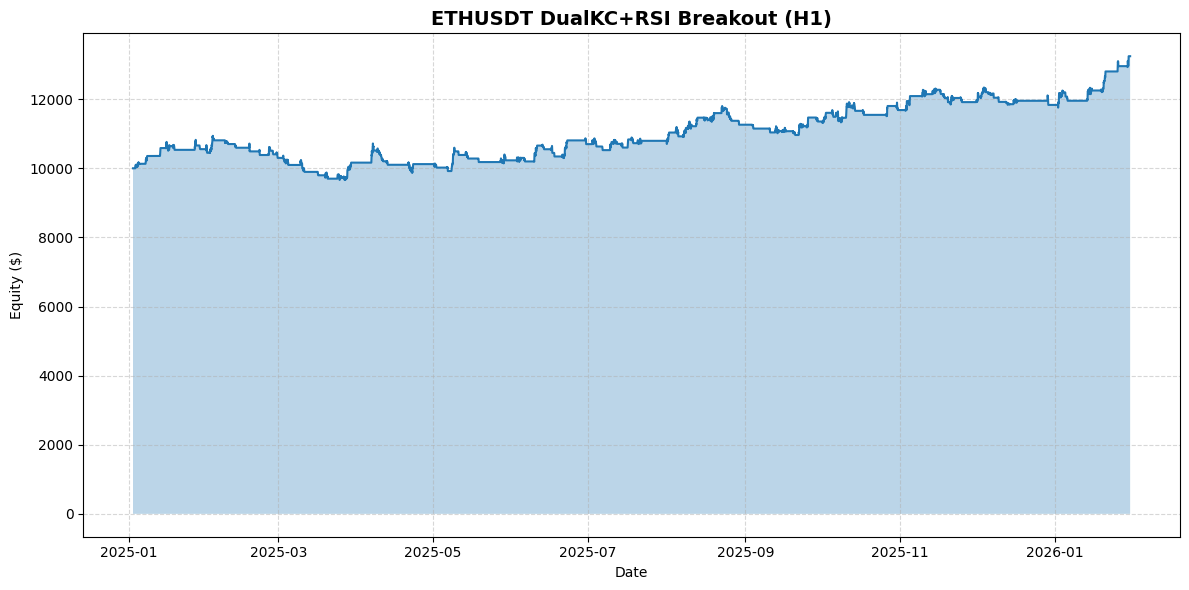


📊 Sample Trades:
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2025-01-05 06:00:00   LONG  3565.140000  3639.080000  130.134400    Time Exit  10130.134400
1 2025-01-08 06:00:00  SHORT  3462.650000  3327.780566  225.231955  Take Profit  10355.366355
2 2025-01-13 13:00:00  SHORT  3170.382773  3038.843979  230.192889  Take Profit  10585.559244
3 2025-01-17 05:00:00   LONG  3329.490000  3366.710000   54.341200    Time Exit  10639.900444
4 2025-01-19 02:00:00  SHORT  3284.675911  3371.161417 -106.377173    Stop Loss  10533.523272
5 2025-01-27 06:00:00  SHORT  3214.130000  3106.781422  234.019899  Take Profit  10767.543171
6 2025-01-27 13:00:00  SHORT  3070.800000  3133.584705 -107.361846    Stop Loss  10660.181325
7 2025-01-29 04:00:00  SHORT  3055.447181  3134.879761 -106.439658    Stop Loss  10553.741667
8 2025-01-31 21:00:00   LONG  3350.700000  3281.424940 -105.298091    Stop Loss  10448.443576
9 2025-02-02 17:00:00  SHORT  3149.790000 

In [ ]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
#    Strategy requires:
#    - Typical Price
#    - RSI(20) on Typical Price
#    - ATR(14) for entry buffer
#    - ATR(20) for SL & TP
#    - Keltner Channels:
#        KC(20, dev=2.0)
#        KC(49, dev=2.3)
#    - Highest/Lowest Close window=15 (shift=3 applied in backtest)
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Typical Price = (H+L+C)/3
    data["Typical_Price"] = (data["High"] + data["Low"] + data["Close"]) / 3.0

    # True Range
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # ATR (Wilder EMA)
    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_14"] = calc_atr(data["TR"], 14)
    data["ATR_20"] = calc_atr(data["TR"], 20)

    # RSI (rolling mean style, giống template bạn đưa)
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_20_TP"] = calc_rsi(data["Typical_Price"], 20)

    # Keltner Channel helper: EMA(Close, period) ± dev * ATR(period)
    def keltner_channel(df_in: pd.DataFrame, period: int, dev: float):
        ema = df_in["Close"].ewm(span=period, adjust=False).mean()
        atr = calc_atr(df_in["TR"], period)
        upper = ema + dev * atr
        lower = ema - dev * atr
        return upper, lower

    # KC(20, dev=2.0) (ngắn)
    data["KC_Upper_20"], data["KC_Lower_20"] = keltner_channel(data, 20, 2.0)

    # KC(49, dev=2.3) (dài)
    data["KC_Upper_49"], data["KC_Lower_49"] = keltner_channel(data, 49, 2.3)

    # Highest/Lowest Close window=15 (shift handled in backtest via i-3)
    data["Highest_Close_15"] = data["Close"].rolling(window=15).max()
    data["Lowest_Close_15"] = data["Close"].rolling(window=15).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER
#    Signals:
#      Long:
#        Open(t) > KC20_up(t-1) AND Open(t) > KC49_up(t-1)
#        AND RSI(shift=2) < RSI(shift=1)  => rsi[t-2] < rsi[t-1]
#      Short:
#        Open(t) < KC20_lo(t-1) AND Open(t) < KC49_lo(t-1)
#        AND RSI(shift=2) > RSI(shift=1)  => rsi[t-2] > rsi[t-1]
#
#    Entry STOP:
#      Long: BuyStop = Highest(Close,15,shift=3) + 2.4 * ATR14(shift=1)
#      Short: SellStop = Lowest(Close,15,shift=3) - 2.4 * ATR14(shift=1)
#      Pending expiration = 3 bars
#
#    Exit:
#      SL = 2.2 * ATR20(shift=1)
#      TP = 4.9 * ATR20(shift=1)   (TP cũng dùng ATR20)
#      ExitAfterBars = 38
# =========================================================
class DualKCRSIBreakoutBacktester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0

        self.pending_order = None

        # Params (đúng mô tả)
        self.price_entry_mult = 2.4
        self.sl_coef = 2.2
        self.tp_coef = 4.9
        self.exit_after_bars = 38
        self.pending_expiration = 3

        # Money management
        self.risk_pct = 0.01
        self.mm_max_lots = 100.0
        self.mm_decimals = 2

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            idx = indices[i]

            # -------------------------------------------------
            # A) MANAGE OPEN POSITION: SL/TP/Time-exit
            # -------------------------------------------------
            if self.position is not None:
                bars_held = i - self.entry_bar_idx

                if bars_held >= self.exit_after_bars:
                    self.close_position(bar["Close"], idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

            # -------------------------------------------------
            # B) MANAGE PENDING ORDER: expiration + fill
            # -------------------------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p_price = self.pending_order["price"]
                    if self.pending_order["type"] == "BUY_STOP" and bar["High"] >= p_price:
                        fill_price = max(p_price, bar["Open"])
                        self.open_position(
                            "LONG", fill_price, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP" and bar["Low"] <= p_price:
                        fill_price = min(p_price, bar["Open"])
                        self.open_position(
                            "SHORT", fill_price, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

            # -------------------------------------------------
            # C) SIGNALS -> PLACE PENDING
            # -------------------------------------------------
            if self.position is None and self.pending_order is None:
                # Need:
                # - KC shift=1 => i>=1
                # - RSI shift=2 vs shift=1 => i>=2
                # - Highest/Lowest shift=3 => i>=3
                if i < 3:
                    self.append_equity(idx)
                    continue

                open_0 = bar["Open"]

                # KC shift=1
                kc20_up_1 = self.df.iloc[i-1]["KC_Upper_20"]
                kc20_lo_1 = self.df.iloc[i-1]["KC_Lower_20"]
                kc49_up_1 = self.df.iloc[i-1]["KC_Upper_49"]
                kc49_lo_1 = self.df.iloc[i-1]["KC_Lower_49"]

                # RSI slope check: shift=2 vs shift=1  => rsi[i-2] vs rsi[i-1]
                rsi_2 = self.df.iloc[i-2]["RSI_20_TP"]
                rsi_1 = self.df.iloc[i-1]["RSI_20_TP"]

                long_signal = (open_0 > kc20_up_1) and (open_0 > kc49_up_1) and (rsi_2 < rsi_1)
                short_signal = (open_0 < kc20_lo_1) and (open_0 < kc49_lo_1) and (rsi_2 > rsi_1)

                if (not long_signal) and (not short_signal):
                    self.append_equity(idx)
                    continue

                # Entry uses Highest/Lowest(Close,15,shift=3) => take rolling value at i-3
                highest_close_shift3 = self.df.iloc[i-3]["Highest_Close_15"]
                lowest_close_shift3 = self.df.iloc[i-3]["Lowest_Close_15"]

                # Entry buffer uses ATR(14, shift=1) (đúng mô tả)
                atr14_shift1 = self.df.iloc[i-1]["ATR_14"]

                # SL/TP distances use ATR(20, shift=1)
                atr20_shift1 = self.df.iloc[i-1]["ATR_20"]
                sl_dist = self.sl_coef * atr20_shift1
                tp_dist = self.tp_coef * atr20_shift1

                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr14_shift1)
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr14_shift1)
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            # -------------------------------------------------
            # D) APPEND EQUITY
            # -------------------------------------------------
            self.append_equity(idx)

    def append_equity(self, idx):
        mtm = self.balance
        close_price = self.df.loc[idx, "Close"]
        if self.position == "LONG":
            mtm += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_price) * self.qty
        self.equity_curve.append({"time": idx, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk sizing
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        # Apply caps/rounding like template
        qty = min(qty, self.mm_max_lots)
        qty = np.floor(qty * (10 ** self.mm_decimals)) / (10 ** self.mm_decimals)
        self.qty = float(qty)

    def close_position(self, price: float, time_idx, reason: str):
        price = float(price)
        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl
        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = dd.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df["PnL"] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df[trades_df["PnL"] > 0]["PnL"].sum()
    gross_loss = abs(trades_df[trades_df["PnL"] < 0]["PnL"].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*60)
    print("🎯 STRATEGY - Dual KC(20/49) + RSI(20 TypicalPrice) + STOP(Highest/Lowest Close 15) + ATR14 buffer")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    rr = (metrics["Profit Factor"] * (1 - metrics["Winrate"])) / metrics["Winrate"] if metrics["Winrate"] > 0 else 0
    print(f"\n💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)

    plt.title(f"{symbol} DualKC+RSI Breakout (H1)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "30/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 400:
        print("✅ Data ready...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Running Strategy_1_25_164...")
        bt = DualKCRSIBreakoutBacktester(df_calc, initial_balance=10000.0)
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())
        else:
            print("⚠️ No trades.")
    else:
        print("❌ Insufficient data.")
